In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

# Load dataset
df = pd.read_csv("fakenews.csv")

# Handle missing values
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

# Display first five rows
print(df[["label", "text"]].head())

print("\nTotal articles:", len(df))
print("Dataset loaded successfully!")

  label                                               text
0  Real  Global economy faces recession The Prime Minis...
1  Real  Earthquake hits Chittagong, panic spreads Gove...
2  Fake  Breakthrough in Bangladesh's tech industry Loc...
3  Fake  Dengue situation worsens in the country The Pr...
4  Real  New virus outbreak sparks fear Government sour...

Total articles: 2212
Dataset loaded successfully!


In [2]:
# Create a bigram vectorizer
bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    stop_words="english",
    max_features=1000
)

# Analyze bigrams separately for each news label
for label in df["label"].dropna().unique():

    # Select articles for the current label
    texts = df.loc[df["label"] == label, "text"]

    # Calculate bigram frequencies
    bigram_matrix = bigram_vectorizer.fit_transform(texts)

    # Get bigram names and their frequencies
    bigrams = bigram_vectorizer.get_feature_names_out()
    frequencies = bigram_matrix.sum(axis=0).A1

    # Create a frequency DataFrame
    bigram_df = pd.DataFrame({
        "Bigram": bigrams,
        "Frequency": frequencies
    })

    # Display the top 10 bigrams
    top_bigrams = bigram_df.sort_values(
        by="Frequency",
        ascending=False
    ).head(10)

    print(f"\nTop 10 Bigrams in {label} News:")
    print(top_bigrams)


Top 10 Bigrams in Real News:
                     Bigram  Frequency
10          bangladesh wins        141
179              wins world        141
181               world cup        141
93               media noon        130
110               news went        130
178              went viral        130
156            social media        130
175            viral social        130
91     local administration        122
0    administration visited        122

Top 10 Bigrams in Fake News:
                      Bigram  Frequency
4         astronaut captures        135
16            captures photo        135
11     bangladeshi astronaut        135
115               photo moon        135
6      authenticity incident        129
140     remains authenticity        129
173      uncertainty remains        129
171            tech industry        128
14   breakthrough bangladesh        128
9            bangladesh tech        128


In [3]:
# Create a trigram vectorizer
trigram_vectorizer = CountVectorizer(
    ngram_range=(3, 3),
    stop_words="english",
    max_features=1000
)

# Analyze trigrams separately for each news label
for label in df["label"].dropna().unique():

    # Select articles for the current label
    texts = df.loc[df["label"] == label, "text"]

    # Calculate trigram frequencies
    trigram_matrix = trigram_vectorizer.fit_transform(texts)

    # Get trigram names and their frequencies
    trigrams = trigram_vectorizer.get_feature_names_out()
    frequencies = trigram_matrix.sum(axis=0).A1

    # Create a frequency DataFrame
    trigram_df = pd.DataFrame({
        "Trigram": trigrams,
        "Frequency": frequencies
    })

    # Display the top 10 trigrams
    top_trigrams = trigram_df.sort_values(
        by="Frequency",
        ascending=False
    ).head(10)

    print(f"\nTop 10 Trigrams in {label} News:")
    print(top_trigrams)


Top 10 Trigrams in Real News:
                          Trigram  Frequency
6           bangladesh wins world        141
242                wins world cup        141
238            viral social media        130
241             went viral social        130
140               news went viral        130
203             social media noon        130
122  local administration visited        122
0     administration visited spot        122
240       visited spot inspection        122
189     residents claim witnessed        121

Top 10 Trigrams in Fake News:
                                   Trigram  Frequency
3                 astronaut captures photo        135
12                     captures photo moon        135
7           bangladeshi astronaut captures        135
187          remains authenticity incident        129
236       uncertainty remains authenticity        129
10            breakthrough bangladesh tech        128
5                 bangladesh tech industry        128
53         

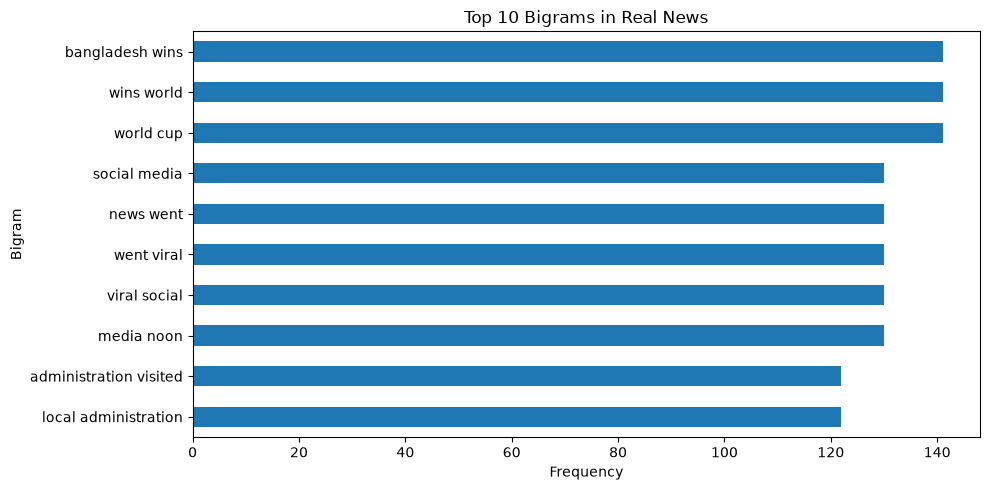

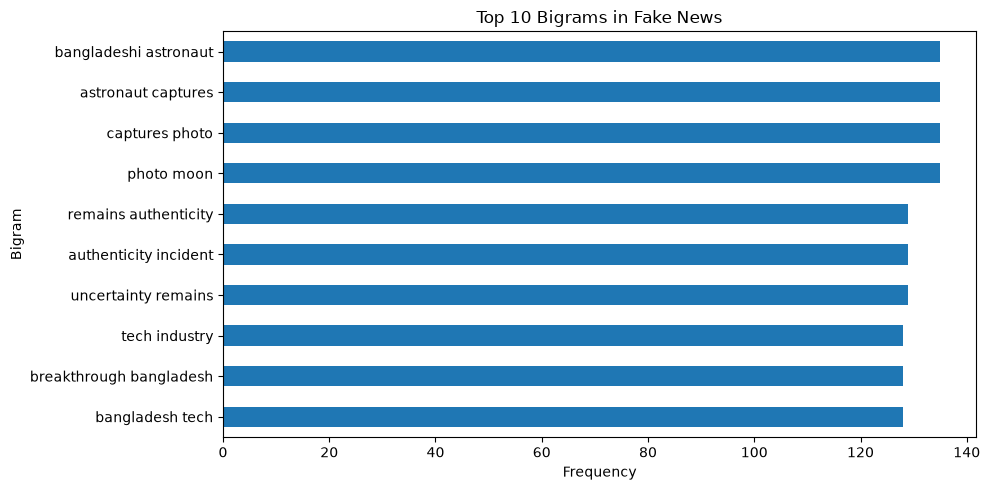

In [5]:
# Graphs for bigrams and trigrams
for label in df["label"].dropna().unique():

    texts = df.loc[df["label"] == label, "text"]

    # Calculate bigram frequencies
    bigram_vectorizer = CountVectorizer(
        ngram_range=(2, 2),
        stop_words="english",
        max_features=1000
    )

    bigram_matrix = bigram_vectorizer.fit_transform(texts)

    bigram_df = pd.DataFrame({
        "Phrase": bigram_vectorizer.get_feature_names_out(),
        "Frequency": bigram_matrix.sum(axis=0).A1
    })

    top_bigrams = bigram_df.nlargest(10, "Frequency")

    # Plot top 10 bigrams
    plt.figure(figsize=(10, 5))
    top_bigrams.sort_values("Frequency").plot(
        x="Phrase",
        y="Frequency",
        kind="barh",
        legend=False,
        ax=plt.gca()
    )

    plt.title(f"Top 10 Bigrams in {label} News")
    plt.xlabel("Frequency")
    plt.ylabel("Bigram")
    plt.tight_layout()
    plt.show()

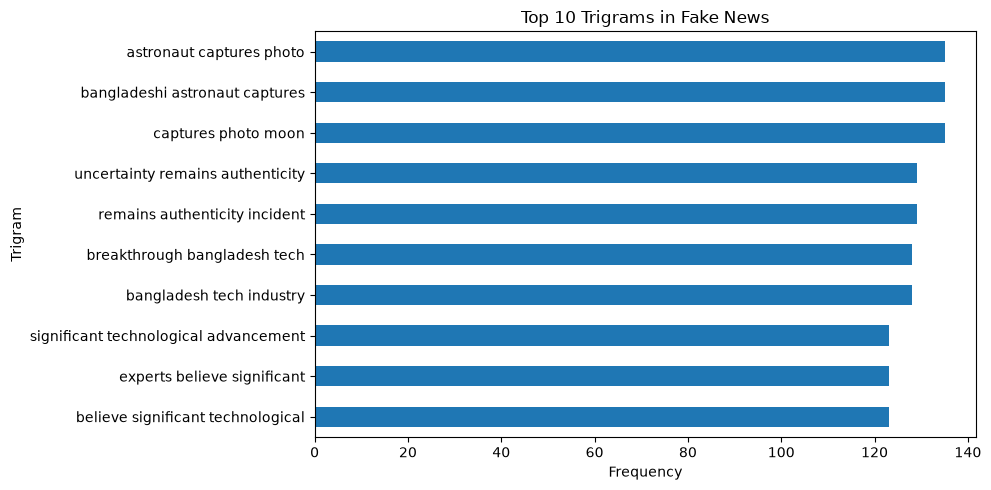

In [6]:

    # Calculate trigram frequencies
    trigram_vectorizer = CountVectorizer(
        ngram_range=(3, 3),
        stop_words="english",
        max_features=1000
    )

    trigram_matrix = trigram_vectorizer.fit_transform(texts)

    trigram_df = pd.DataFrame({
        "Phrase": trigram_vectorizer.get_feature_names_out(),
        "Frequency": trigram_matrix.sum(axis=0).A1
    })

    top_trigrams = trigram_df.nlargest(10, "Frequency")

    # Plot top 10 trigrams
    plt.figure(figsize=(10, 5))
    top_trigrams.sort_values("Frequency").plot(
        x="Phrase",
        y="Frequency",
        kind="barh",
        legend=False,
        ax=plt.gca()
    )

    plt.title(f"Top 10 Trigrams in {label} News")
    plt.xlabel("Frequency")
    plt.ylabel("Trigram")
    plt.tight_layout()
    plt.show()

In [7]:
# Compare bigram frequencies
bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    stop_words="english",
    max_features=1000
)

bigram_matrix = bigram_vectorizer.fit_transform(df["text"])
bigram_names = bigram_vectorizer.get_feature_names_out()

bigram_results = pd.DataFrame(
    bigram_matrix.toarray(),
    columns=bigram_names
)
bigram_results["label"] = df["label"].values

bigram_comparison = bigram_results.groupby("label").sum().T

print("Top Bigrams by News Label:")
for label in bigram_comparison.columns:
    print(f"\n{label} News:")
    print(
        bigram_comparison[label]
        .sort_values(ascending=False)
        .head(10)
    )

# Compare trigram frequencies
trigram_vectorizer = CountVectorizer(
    ngram_range=(3, 3),
    stop_words="english",
    max_features=1000
)

trigram_matrix = trigram_vectorizer.fit_transform(df["text"])
trigram_names = trigram_vectorizer.get_feature_names_out()

trigram_results = pd.DataFrame(
    trigram_matrix.toarray(),
    columns=trigram_names
)
trigram_results["label"] = df["label"].values

trigram_comparison = trigram_results.groupby("label").sum().T

print("\nTop Trigrams by News Label:")
for label in trigram_comparison.columns:
    print(f"\n{label} News:")
    print(
        trigram_comparison[label]
        .sort_values(ascending=False)
        .head(10)
    )

Top Bigrams by News Label:

Fake News:
astronaut captures         135
captures photo             135
bangladeshi astronaut      135
photo moon                 135
authenticity incident      129
remains authenticity       129
uncertainty remains        129
tech industry              128
breakthrough bangladesh    128
bangladesh tech            128
Name: Fake, dtype: int64

Real News:
bangladesh wins           141
wins world                141
world cup                 141
media noon                130
news went                 130
went viral                130
social media              130
viral social              130
local administration      122
administration visited    122
Name: Real, dtype: int64

Top Trigrams by News Label:

Fake News:
astronaut captures photo                 135
captures photo moon                      135
bangladeshi astronaut captures           135
remains authenticity incident            129
uncertainty remains authenticity         129
breakthrough bangladesh

In [9]:
# Save bigram comparison
bigram_comparison.to_csv("T17_bigram_comparison.csv")

# Save trigram comparison
trigram_comparison.to_csv("T17_trigram_comparison.csv")

print("Task 17 completed successfully!")

print("\nFiles saved:")
print("1. T17_bigram_comparison.csv")
print("2. T17_trigram_comparison.csv")


Task 17 completed successfully!

Files saved:
1. T17_bigram_comparison.csv
2. T17_trigram_comparison.csv
